In [2]:
from datasets import load_dataset
from huggingface_hub import hf_hub_download
import pandas as pd
import numpy as np
from datetime import datetime
import sentencepiece as spm
import matplotlib.pyplot as plt

/u701/m4sedagh/.conda/envs/attention-is-all-you-need/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


IWSLT17

In [ ]:
path = hf_hub_download(
    repo_id="IWSLT/iwslt2017",
    filename="data/2017-01-trnted/texts/de/en/de-en.zip",
    repo_type="dataset",
    local_dir="./cache/"
)

In [ ]:
!unzip $path -d ./cache/data/content/de-en/

/bin/bash: line 1: unzip: command not found


In [10]:
!cat ./cache/data/content/de-en/de-en/train.tags.de-en.en | head -2

<doc docid="1" genre="lectures"> 
<url>http://www.ted.com/talks/al_gore_on_averting_climate_crisis</url> 
cat: write error: Broken pipe


In [11]:
import xml.etree.ElementTree as ET
from pathlib import Path


def _language_from_path(path: str):
    name = Path(path).name.lower()
    if ".de." in name or name.endswith(".de"):
        return "de"
    if ".en." in name or name.endswith(".en"):
        return "en"
    return None


def _text(parent, tag: str):
    element = parent.find(tag)
    return element.text.strip() if element is not None and element.text else None


def _person(parent, tag: str):
    element = parent.find(tag)
    if element is None:
        return None
    return {
        "name": element.text.strip() if element.text else None,
        "href": element.attrib.get("href"),
    }


def _document_from_element(doc, *, segments_are_elements: bool):
    document = {
        "docid": doc.attrib.get("docid"),
        "genre": doc.attrib.get("genre"),
        "url": _text(doc, "url"),
        "description": _text(doc, "description"),
        "keywords": _text(doc, "keywords"),
        "speaker": _text(doc, "speaker"),
        "talkid": _text(doc, "talkid"),
        "title": _text(doc, "title"),
        "reviewer": _person(doc, "reviewer"),
        "translator": _person(doc, "translator"),
        "segments": [],
    }

    if segments_are_elements:
        document["segments"] = [
            {"id": segment.attrib.get("id"), "text": (segment.text or "").strip()}
            for segment in doc.findall("seg")
        ]
    else:
        lines = []
        for child in doc:
            lines.extend(line.strip() for line in (child.tail or "").splitlines() if line.strip())
        document["segments"] = [
            {"id": str(index), "text": text}
            for index, text in enumerate(lines, start=1)
        ]

    return document


def parse_test(path: str):
    root = ET.parse(path).getroot()
    container = root if root.tag in {"srcset", "refset"} else root.find("srcset")
    if container is None:
        container = root.find("refset")
    if container is None:
        raise ValueError(f"No <srcset> or <refset> found in {path}")

    return {
        "setid": container.attrib.get("setid"),
        "srclang": container.attrib.get("srclang"),
        "language": _language_from_path(path),
        "documents": [
            _document_from_element(doc, segments_are_elements=True)
            for doc in container.findall("doc")
        ],
    }

In [12]:
def parse_train(path: str):
    file_path = Path(path)
    language = _language_from_path(file_path)
    if language is None:
        raise ValueError("Expected a train.tags.de-en.de or train.tags.de-en.en file")

    # The training files are XML fragments: wrapping them provides one parseable root.
    text = file_path.read_text(encoding="utf-8")
    root = ET.fromstring(f"<corpus>\n{text}\n</corpus>")

    return {
        "setid": "iwslt2017-train",
        "srclang": None,
        "language": language,
        "documents": [
            _document_from_element(doc, segments_are_elements=False)
            for doc in root.findall("doc")
        ],
    }

In [13]:
def turn_into_df(en_path,de_path,*,title=False,train=True):
  # extracting train stuff
  text_dic = []
  title_dic = []
  if train:
    docs_en = parse_train(en_path)
    docs_de = parse_train(de_path)
  else:
    docs_en = parse_test(en_path)
    docs_de = parse_test(de_path)


  for doc_en,doc_de in zip(docs_en['documents'],docs_de['documents']):
    assert(doc_en['docid'] == doc_de['docid'])
    assert(doc_en['talkid'] == doc_de['talkid'])
    assert(doc_en['talkid'] == doc_en['docid'])

    if title:
      title_dic.append({
          "docid": doc_en["docid"],
          "entitle": doc_en["title"],
          "detitle": doc_de["title"],
      })

    for seg_en,seg_de in zip(doc_en['segments'],doc_de['segments']):
      assert(seg_en['id'] == seg_de['id'])
      text_dic.append({
          "index": f"{doc_en['docid']},{seg_en['id']}",
          "docid": doc_en["docid"],
          "segid": seg_en["id"],
          "entext": seg_en["text"],
          "detext": seg_de["text"],
      })


  train_df = pd.DataFrame.from_dict(text_dic)
  title_df = pd.DataFrame.from_dict(title_dic)

  if title:
    return train_df,title_df
  return train_df

In [14]:
train_df,title_df = turn_into_df("./cache/data/content/de-en/de-en/train.tags.de-en.en","./cache/data/content/de-en/de-en/train.tags.de-en.de",title=True)

In [16]:
# validation set:
val_df = turn_into_df("./cache/data/content/de-en/de-en/IWSLT17.TED.dev2010.de-en.en.xml","./cache/data/content/de-en/de-en/IWSLT17.TED.dev2010.de-en.de.xml",train=False)

In [ ]:
train_df = pd.read_csv("data/iwslt17/train_df.csv")
val_df = pd.read_csv("data/iwslt17/val_df.csv")
# title_df = pd.read_csv("data/iwslt17/title_df.csv")

In [9]:
print("# train sentences {:,}".format(train_df.shape[0]))
print("# train docs {:,}".format(title_df.shape[0]))
print("# val sentences {:,}".format(val_df.shape[0]))
train_df.head()

# train sentences 206,112
# train docs 1,705
# val sentences 888


,index,docid,segid,entext,detext
0,"1,1",1,1,"Thank you so much, Chris.","Vielen Dank, Chris."
1,"1,2",1,2,And it's truly a great honor to have the oppor...,"Es ist mir wirklich eine Ehre, zweimal auf die..."
2,"1,3",1,3,"I have been blown away by this conference, and...",Ich bin wirklich begeistert von dieser Konfere...
3,"1,4",1,4,"And I say that sincerely, partly because I ne...","Das meine ich ernst, teilweise deshalb -- weil..."
4,"1,5",1,5,Put yourselves in my position.,Versetzen Sie sich mal in meine Lage!


In [8]:
train_df.to_csv("data/iwslt17/train_df.csv",index=False)
val_df.to_csv("data/iwslt17/val_df.csv",index=False)
title_df.to_csv("data/iwslt17/title_df.csv",index=False)

In [4]:
sp_bpe = spm.SentencePieceProcessor()
sp_bpe.load(f"tokenizers/iwslt17/bpe.model")
def encode(item):
    ids = sp_bpe.encode_as_ids(item, add_bos=True, add_eos=True)
    return np.array(ids, dtype=np.int64)

In [ ]:
def filter(df:pd.DataFrame,*,br_remove=True,braket_remove=True,duplicate_limit=10,duplicate_left=5,min_token=4,max_ratio=2,sort=False):
    print(f"start count: {df.shape[0]}")
    if br_remove:
        print(f"br_remove, updated: {df["detext"].str.contains("<br").sum()}")
        df["detext"] = df["detext"].str.replace("<br","") # removing parsing issues. 

    if braket_remove:
        print(f"braket_remove, updated: {df['entext'].str.contains(r"\[.*\]\s+","",regex=True).sum() + df['detext'].str.contains(r"\[.*\]\s+","",regex=True).sum()}")
        df["entext"] = df['entext'].str.replace(r"\[.*\]\s+","",regex=True) # removing speaker comments
        df["detext"] = df['detext'].str.replace(r"\[.*\]\s+","",regex=True) # removing speaker comments

    df['en_enc'] = [len(encode(item)) for item in df["entext"]]
    df['de_enc'] = [len(encode(item)) for item in df["detext"]]
    df['ratio'] = df['en_enc'] / df['de_enc']

    en_value_counts = df.groupby("entext")["entext"].transform("count")
    de_value_counts = df.groupby("detext")["detext"].transform("count")
    en_counter = df.groupby("entext").cumcount()
    de_counter = df.groupby("detext").cumcount()

    duplicate_mask = (
        ((en_value_counts < duplicate_limit) | (en_counter < duplicate_left)) & 
        ((de_value_counts < duplicate_limit) | (de_counter < duplicate_left))
    )
    
    length_mask = (
        (df["en_enc"] >= min_token) & 
        (df["de_enc"] >= min_token)
    )
    ratio_mask = (df["ratio"] >= (1/max_ratio)) & (df["ratio"] <= max_ratio)
    print(f"duplicate mask removed: {(~duplicate_mask).sum()} + length mask removed: {(~length_mask).sum()} + ratio mask remvoed: {(~ratio_mask).sum()}")
    df = df[duplicate_mask & length_mask & ratio_mask]

    print("final ratio")
    plt.hist(df["ratio"])
    plt.show()

    print("en encoding dist")
    plt.hist(df["en_enc"])
    plt.show()

    print("de encoding dist")
    plt.hist(df["de_enc"])
    plt.show()

    print(f"final count: {df.shape[0]}")
    if sort:
        df = df.sort_values("en_enc").reset_index()
    df = df.drop(columns=["en_enc","de_enc","ratio"])
    return df

br_remove, updated: 0
braket_remove, updated: 6
duplicate mask removed: 9 + length mask removed: 0 + ratio mask remvoed: 1
final ratio


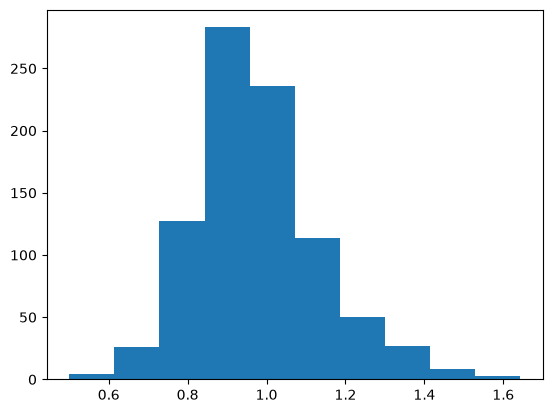

en encoding dist


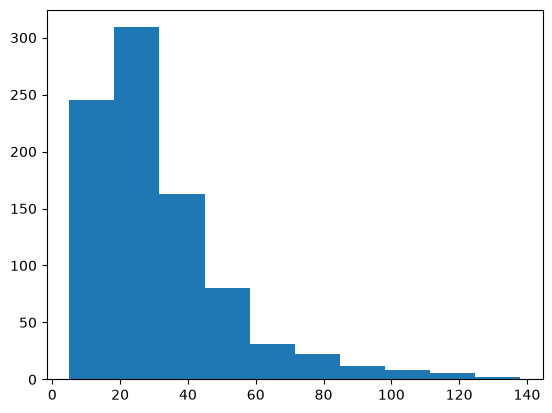

de encoding dist


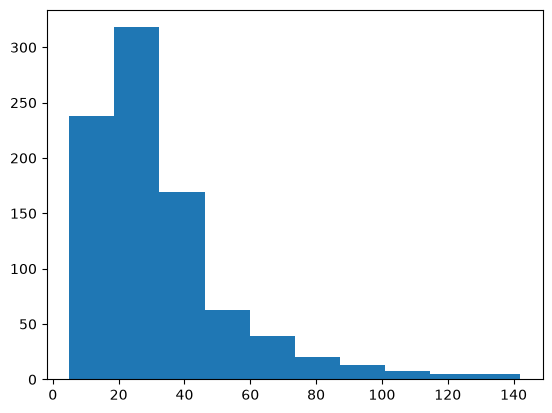

In [75]:
val_df = pd.read_csv("data/iwslt17/val_df.csv")
filtered_df = val_df.copy()
filtered_df = filter(filtered_df,sort=True,duplicate_limit=2,duplicate_left=1)
filtered_df.to_csv("data/iwslt17_curated/val_df.csv")

br_remove, updated: 97
braket_remove, updated: 986
duplicate mask removed: 1472 + length mask removed: 12 + ratio mask remvoed: 434
final ratio


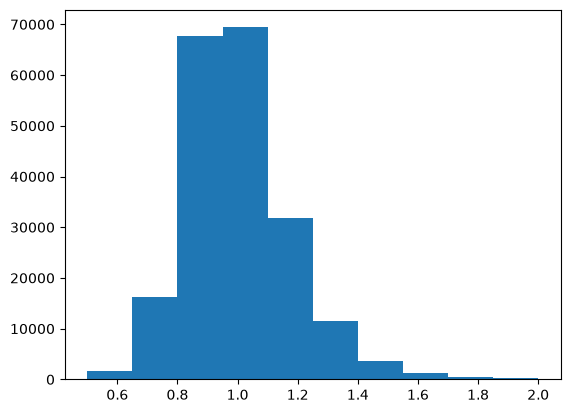

en encoding dist


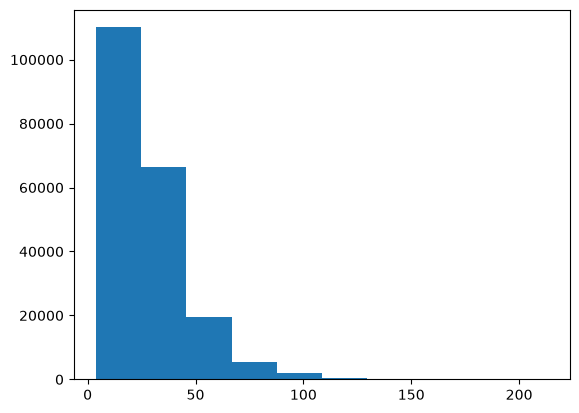

de encoding dist


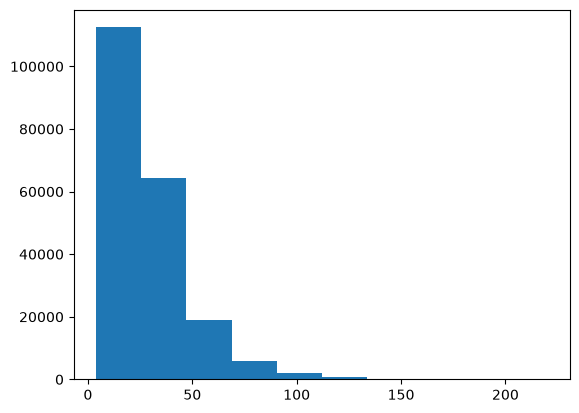

In [76]:
train_df = pd.read_csv("data/iwslt17/train_df.csv")
filtered_df = train_df.copy()
filtered_df = filter(filtered_df,duplicate_limit=10,duplicate_left=5)
filtered_df.to_csv("data/iwslt17_curated/train_df.csv")

In [48]:
with pd.option_context('display.max_colwidth',None):
    print(val_df[val_df["ratio"] >= 1.70][["entext","detext"]])

                                                                                                                                                                                          entext  \
795  And I think it makes the world look like this. [And lastly, for all eternity, French, bleu cheese, or ranch?]    You really want to get the decision right if it's for all eternity, right?   
805                                                      Here's an example. [I can't stop thinking about those other available parking spaces on W 85th street] Sorry if you're not New Yorkers.   
842                                                                    [It all looks so great. I can't wait to be disappointed.] Because if they did, you wouldn't all know what this was about.   

                                                                                                                                                      detext  
795  Und ich denke es sorgt dafür, dass die Welt so auss

WMT14

In [80]:
# Loading the train set:
ds = load_dataset("wmt/wmt14", "de-en",split="train",streaming=True)

for idx,row in enumerate(ds.iter(batch_size=8192)):
    df=pd.DataFrame(row["translation"])
    df["entext"] = df["en"].str.split().str.join(" ")
    df["detext"] = df["de"].str.split().str.join(" ")
    df = df.drop(columns=["de","en"])
    if idx == 0:
        df.to_csv("wmt14_train.csv",mode="w",index=False,header=True)
    else:
        df.to_csv("wmt14_train.csv",mode="a",index=False,header=False)
    print(f"{datetime.now()}: At index: {idx}")

2026-09-24 09:25:01.735060: At index: 0
2026-09-24 09:25:01.795568: At index: 1
2026-09-24 09:25:01.853556: At index: 2
2026-09-24 09:25:01.913816: At index: 3
2026-09-24 09:25:01.971482: At index: 4
2026-09-24 09:25:02.029482: At index: 5
2026-09-24 09:25:02.087476: At index: 6
2026-09-24 09:25:02.145305: At index: 7
2026-09-24 09:25:02.206310: At index: 8
2026-09-24 09:25:02.265110: At index: 9
2026-09-24 09:25:02.323626: At index: 10
2026-09-24 09:25:02.470415: At index: 11
2026-09-24 09:25:02.529612: At index: 12
2026-09-24 09:25:02.590618: At index: 13
2026-09-24 09:25:02.649939: At index: 14
2026-09-24 09:25:02.707668: At index: 15
2026-09-24 09:25:02.766263: At index: 16
2026-09-24 09:25:02.826243: At index: 17
2026-09-24 09:25:02.884295: At index: 18
2026-09-24 09:25:02.943723: At index: 19
2026-09-24 09:25:03.002682: At index: 20
2026-09-24 09:25:05.826648: At index: 21
2026-09-24 09:25:05.885074: At index: 22
2026-09-24 09:25:05.941686: At index: 23
2026-09-24 09:25:05.996466

In [82]:
# Loading the val set: 
ds = load_dataset("wmt/wmt14", "de-en",split="validation",streaming=True)
for idx,row in enumerate(ds.iter(batch_size=8192)):
    df=pd.DataFrame(row["translation"])
    df["entext"] = df["en"].str.split().str.join(" ")
    df["detext"] = df["de"].str.split().str.join(" ")
    df = df.drop(columns=["de","en"])
    if idx == 0:
        df.to_csv("wmt14_val.csv",mode="w",index=False,header=True)
    else:
        df.to_csv("wmt14_val.csv",mode="a",index=False,header=False)
    print(f"{datetime.now()}: At index: {idx}")

2026-09-24 09:27:12.905908: At index: 0


In [ ]:
sp_bpe = sentencepiece.SentencePieceProcessor()
sp_bpe.load("tokenizers/wmt14/bpe.model")
NUM_TOKENS=0
def encode(item):
        global NUM_TOKENS
        ids = sp_bpe.encode_as_ids(item, add_bos=True, add_eos=True)
        NUM_TOKENS+=len(ids)
        return np.array(ids, dtype=np.int64)

In [ ]:
# Sorting val df for faster validation calculation (batches of same size get grouped together)
val_df = pd.read_csv("wmt14_val.csv")
val_df['en_enc'] = [len(encode(item)) for item in val_df["entext"]]
val_df['de_enc'] = [len(encode(item)) for item in val_df["detext"]]
val_df['ratio'] = val_df['en_enc'] / val_df['de_enc']
sorted_val_df = val_df.sort_values("en_enc")
print(NUM_TOKENS)
(sorted_val_df.drop(columns=["en_enc","de_enc","ratio"])).to_csv("wmt14_val.csv",index=False)

303892


In [71]:
df = pd.read_csv("wmt14_train.csv",nrows=1000)

In [ ]:
df['en_enc'] = [len(encode(item)) for item in df["entext"]]
df['de_enc'] = [len(encode(item)) for item in df["detext"]]
df['ratio'] = df['en_enc'] / df['de_enc']
sorted_df = df.sort_values("en_enc")
print(NUM_TOKENS)

92366


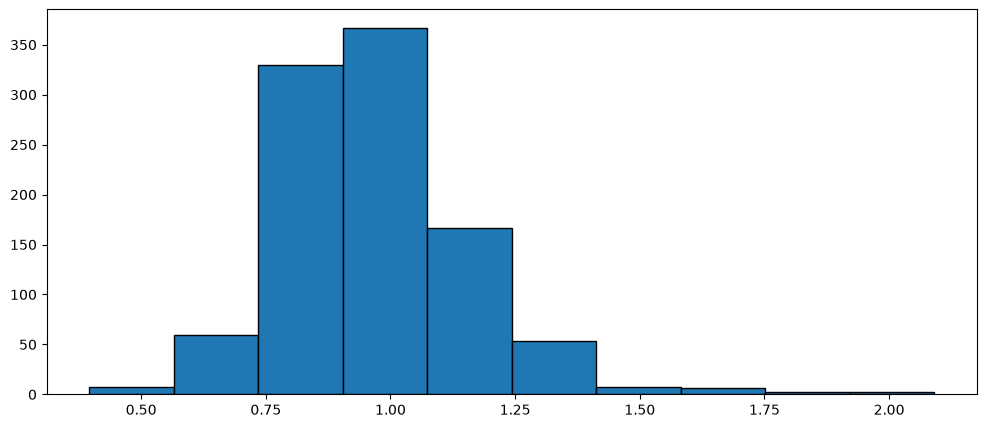

In [73]:
plt.figure(figsize=(12,5))
plt.hist(df["ratio"],edgecolor="black")
# plt.axline(xy1=(128,0),xy2=(128,25),color="green")
plt.show()

In [76]:
df[df["ratio"] == df["ratio"].max()].iloc[0,1]

'Das dritte Ziel besteht in einer städtischen und ländlichen Entwicklung im Rahmen einer ausgewogenen Raumordnungspolitik.'

In [77]:
df.iloc[571,1]

'Die Leitlinien gehen im übrigen von zwei horizontalen Prinzipien aus: Die Entwicklung des ländlichen Raums - und die Frage einer nachhaltigen Verkehrsstruktur, Frau Berichterstatterin, die mir seit langem am Herzen liegt, insbesondere seit meiner Zeit als Umweltminister meines Landes, gehört für mich in den Bereich der Entwicklung des ländlichen Raums - und das zweite Prinzip ist die Chancengleichheit, insbesondere zwischen Frauen und Männern, sowie die europäische Beschäftigungsstrategie und die Wirtschafts- und Währungsunion.'

In [62]:
from collections import deque

Data Filtering

In [ ]:
NUM_TOKENS=0
val_df = pd.read_csv("val_sorted_df.csv")
def encode(item):
        global NUM_TOKENS
        ids = sp_bpe.encode_as_ids(item, add_bos=True, add_eos=True)
        NUM_TOKENS+=len(ids)
        return np.array(ids, dtype=np.int64)
# filter based on ratio. 
val_df['x_enc'] = [len(encode(item)) for item in val_df["entext"]]
# val_df["detext"] = val_df["detext"].str.replace("<br","")
# sorted_df = val_df.sort_values("x_enc").reset_index().drop(columns=["Unnamed: 0", "x_enc", "level_0"])
# sorted_df.to_csv("val_sorted_df.csv",index=False)
print(NUM_TOKENS)

In [ ]:
val_df.iloc[-1,4]

In [ ]:
NUM_TOKENS=0
train_df = pd.read_csv("train_filtered_df.csv").drop(columns=["Unnamed: 0"])
def encode(item):
        global NUM_TOKENS
        ids = sp_bpe.encode_as_ids(item, add_bos=True,add_eos=True)
        NUM_TOKENS+=len(ids)
        return np.array(ids, dtype=np.int64)
# train_df["detext"] = train_df["detext"].str.replace("<br","")
# Remove anything between [...] and ♪ and long sentences. 
train_df['x_enc'] = [len(encode(item)) for item in train_df["entext"]]
train_df['y_enc'] = [len(encode(item)) for item in train_df["detext"]]
train_df["ratio"] = train_df["x_enc"] / train_df["y_enc"]
print(NUM_TOKENS)

In [ ]:
en_value_counts = train_df.groupby("entext")["entext"].transform("count")
de_value_counts = train_df.groupby("detext")["detext"].transform("count")
en_counter = train_df.groupby("entext").cumcount()
de_counter = train_df.groupby("detext").cumcount()
mask = (
    ((en_value_counts < 10) | (en_counter < 5)) & 
    ((de_value_counts < 10) | (de_counter < 5)) & 
    (train_df["x_enc"] >= 4) & 
    (train_df["y_enc"] > 4) & 
    (train_df["ratio"] >= 0.4) & 
    (train_df["ratio"] <= 2.5)
)
filtered_df = train_df[mask]

In [ ]:
filtered_df.head()

In [ ]:
filtered_df.drop(columns=["Unnamed: 0","x_enc","y_enc","ratio"]).to_csv("train_filtered_df.csv")

In [ ]:
mask.value_counts()

Curation

In [ ]:
df = pd.read_csv("data/wmt14/train_df.csv")

In [ ]:
NUM_TOKENS=0
def encode(item):
        global NUM_TOKENS
        ids = sp_bpe.encode_as_ids(item, add_bos=True,add_eos=True)
        NUM_TOKENS+=len(ids)
        return np.array(ids, dtype=np.int64)
# train_df["detext"] = train_df["detext"].str.replace("<br","")
# Remove anything between [...] and ♪ and long sentences. 
df['x_enc'] = [len(encode(item)) for item in df["entext"]]
df['y_enc'] = [len(encode(item)) for item in df["detext"]]
df["ratio"] = df["x_enc"] / df["y_enc"]

In [ ]:
curated_df = df[df['ratio'] < 2].drop(columns=["x_enc","y_enc","ratio"])

hi?


In [ ]:
df.shape[0]-curated_df.shape[0]

98933

In [ ]:
curated_df.to_csv("data/wmt14_curated/train_df.csv")

Val Curation

In [ ]:
df = pd.read_csv("data/wmt14/val_df.csv")

In [ ]:
df['x_enc'] = [len(encode(item)) for item in df["entext"]]
df['y_enc'] = [len(encode(item)) for item in df["detext"]]
df["ratio"] = df["x_enc"] / df["y_enc"]

In [ ]:
sorted_df = df[df["ratio"] < 2]

In [ ]:
sorted_df = sorted_df.sort_values("x_enc").drop(columns=["x_enc","y_enc","ratio"])

In [ ]:
sorted_df.to_csv("data/wmt14_curated/val_df.csv")

In [ ]:
sorted_df.shape,df.shape

((2998, 2), (3000, 5))